# Visualize Touch Sensor Sites

Renders the rodent model with touch sensor site locations visible.
Use this to verify sensor placement before modifying the XML.

In [53]:
%load_ext autoreload
%autoreload 2

import os

os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import mujoco
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [59]:
# Path to the rodent XML
XML_PATH = "/home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent_no_tail_collisions.xml"

# Load model and create data
model = mujoco.MjModel.from_xml_path(XML_PATH)
data = mujoco.MjData(model)

# Make all sensor sites red
for i in range(model.nsite):
    group = model.site_group[i]
    if group == 4:  # sensor sites
        model.site_rgba[i] = [1.0, 0.0, 0.0, 1.0]

# Step once to get a valid pose
mujoco.mj_forward(model, data)

print(f"Model loaded: {model.nbody} bodies, {model.nsite} sites, {model.nsensor} sensors")

Model loaded: 67 bodies, 21 sites, 8 sensors


In [60]:
# List all sites and their properties
SITE_TYPE_NAMES = {
    mujoco.mjtGeom.mjGEOM_SPHERE: "sphere",
    mujoco.mjtGeom.mjGEOM_CAPSULE: "capsule",
    mujoco.mjtGeom.mjGEOM_ELLIPSOID: "ellipsoid",
    mujoco.mjtGeom.mjGEOM_CYLINDER: "cylinder",
    mujoco.mjtGeom.mjGEOM_BOX: "box",
    mujoco.mjtGeom.mjGEOM_MESH: "mesh",
    mujoco.mjtGeom.mjGEOM_PLANE: "plane",
}

print(f"{'Name':<20} {'Group':>5} {'Type':<10} {'Size (mm)':<30} {'Body':<15}")
print("-" * 82)
for i in range(model.nsite):
    name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_SITE, i)
    group = model.site_group[i]
    type_id = int(model.site_type[i])
    site_type = SITE_TYPE_NAMES.get(type_id, f"type_{type_id}")
    size = model.site_size[i] * 1000  # convert to mm
    body_id = model.site_bodyid[i]
    body_name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_BODY, body_id)
    size_str = f"({size[0]:.1f}, {size[1]:.1f}, {size[2]:.1f})"
    print(f"{name:<20} {group:>5} {site_type:<10} {size_str:<30} {body_name:<15}")

Name                 Group Type       Size (mm)                      Body           
----------------------------------------------------------------------------------
hip_L                    3 sphere     (2.2, 5.0, 5.0)                pelvis         
hip_R                    3 sphere     (2.2, 5.0, 5.0)                pelvis         
knee_L                   3 cylinder   (0.6, 4.0, 5.0)                upper_leg_L    
ankle_L                  3 cylinder   (0.6, 2.6, 5.0)                lower_leg_L    
toe_L                    3 cylinder   (0.6, 5.0, 5.0)                foot_L         
sole_L                   4 box        (12.0, 4.0, 2.0)               toe_L          
knee_R                   3 cylinder   (0.6, 4.0, 5.0)                upper_leg_R    
ankle_R                  3 cylinder   (0.6, 2.6, 5.0)                lower_leg_R    
toe_R                    3 cylinder   (0.6, 5.0, 5.0)                foot_R         
sole_R                   4 box        (12.0, 4.0, 2.0)             

In [61]:
# List touch sensors and which site they reference
print("Touch sensors:")
print(f"{'Sensor Name':<25} {'Site Name':<20} {'Site Body':<15} {'Sensor Index':>12}")
print("-" * 75)
for i in range(model.nsensor):
    sensor_type = model.sensor_type[i]
    # mjtSensor.mjSENS_TOUCH == 0
    if sensor_type == mujoco.mjtSensor.mjSENS_TOUCH:
        sensor_name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_SENSOR, i)
        site_id = model.sensor_objid[i]
        site_name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_SITE, site_id)
        body_id = model.site_bodyid[site_id]
        body_name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_BODY, body_id)
        print(f"{sensor_name:<25} {site_name:<20} {body_name:<15} {model.sensor_adr[i]:>12}")

Touch sensors:
Sensor Name               Site Name            Site Body       Sensor Index
---------------------------------------------------------------------------
palm_L                    palm_L               finger_L                   9
palm_R                    palm_R               finger_R                  10
sole_L                    sole_L               toe_L                     11
sole_R                    sole_R               toe_R                     12


In [62]:
# === Rendering configuration ===
RENDER_HEIGHT = 720
RENDER_WIDTH = 960

# Camera to use (options: "close_profile", "back", "side", "side_alt", "top")
CAMERA_NAMES = [ "close_side_front_L", "close_side_front_R", "close_side_hind_L", "close_side_hind_R",]

# Visualization options
scene_option = mujoco.MjvOption()

# Enable site group 4 (sensor sites) — set to 1 to show, 0 to hide
# Groups: [0, 1, 2, 3, 4, 5]
scene_option.sitegroup[:] = [0, 0, 0, 0, 1, 0]  # Only show group 4 (sensors)

# Optional: also show other visual elements
# scene_option.flags[mujoco.mjtVisFlag.mjVIS_JOINT] = True  # Show joints
# scene_option.flags[mujoco.mjtVisFlag.mjVIS_CONTACTPOINT] = True  # Show contacts
# scene_option.flags[mujoco.mjtVisFlag.mjVIS_TRANSPARENT] = True  # Transparent bodies

print("Site groups visible:", list(scene_option.sitegroup))

Site groups visible: [np.uint8(0), np.uint8(0), np.uint8(0), np.uint8(0), np.uint8(1), np.uint8(0)]


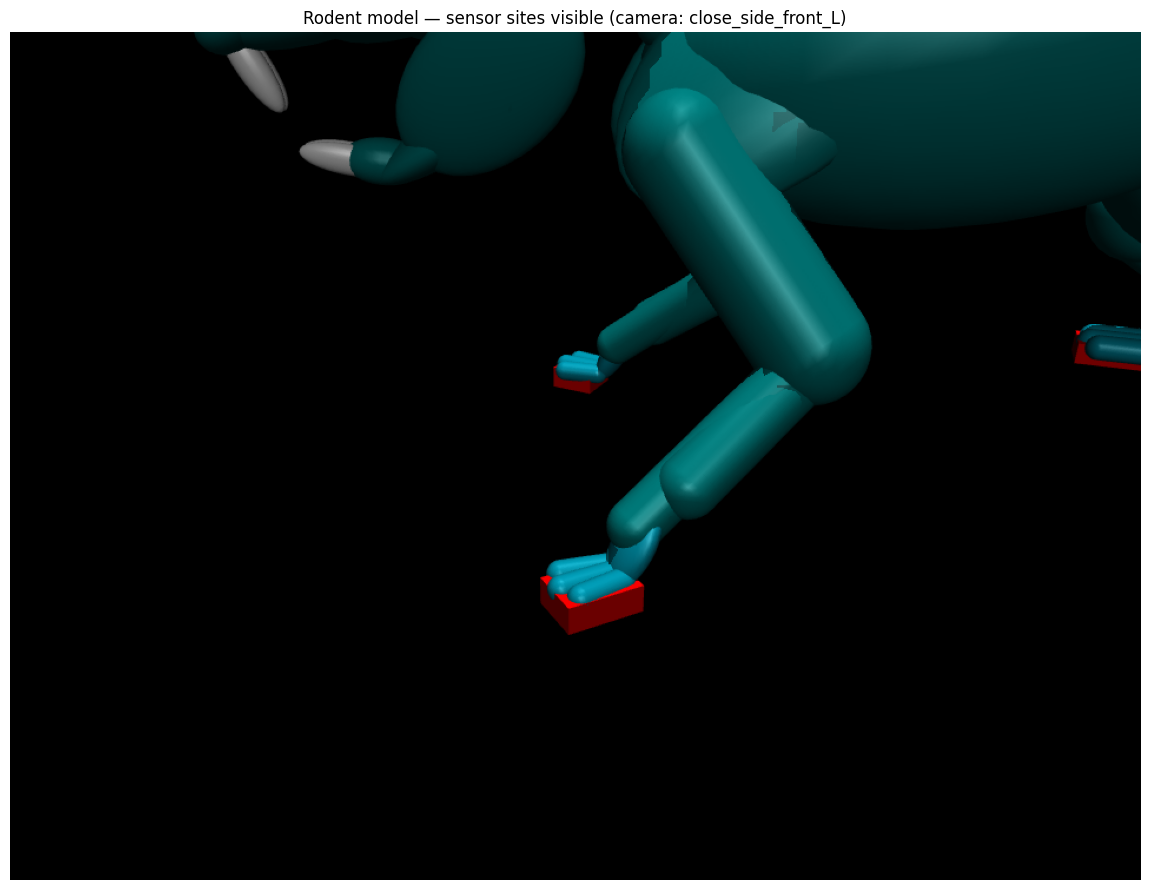


Site world positions (from mj_forward):
  sole_L: [-0.0278, 0.0343, 0.0048]
  sole_R: [-0.0278, -0.0343, 0.0048]
  palm_L: [0.0789, 0.0384, -0.0009]
  palm_R: [0.0799, -0.0384, -0.0009]
  head: [0.0972, 0.0000, 0.0725]


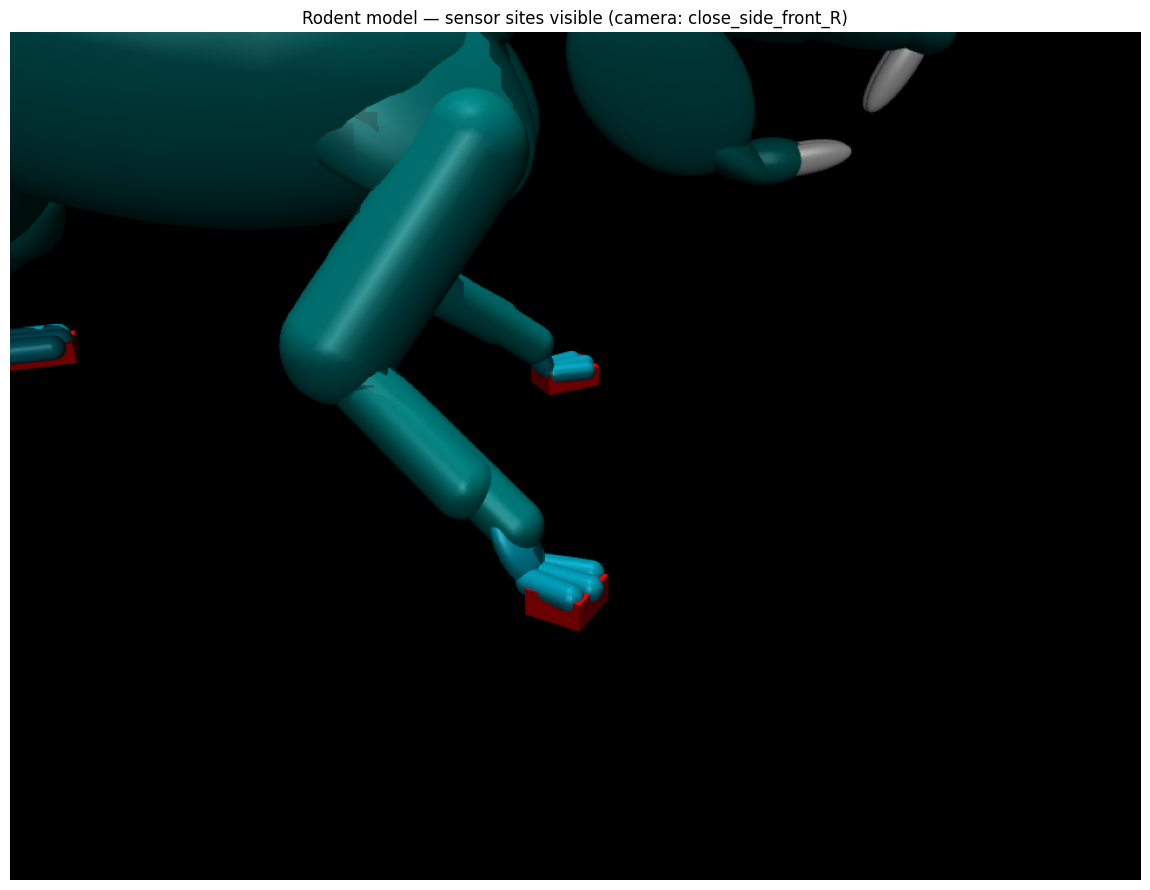


Site world positions (from mj_forward):
  sole_L: [-0.0278, 0.0343, 0.0048]
  sole_R: [-0.0278, -0.0343, 0.0048]
  palm_L: [0.0789, 0.0384, -0.0009]
  palm_R: [0.0799, -0.0384, -0.0009]
  head: [0.0972, 0.0000, 0.0725]


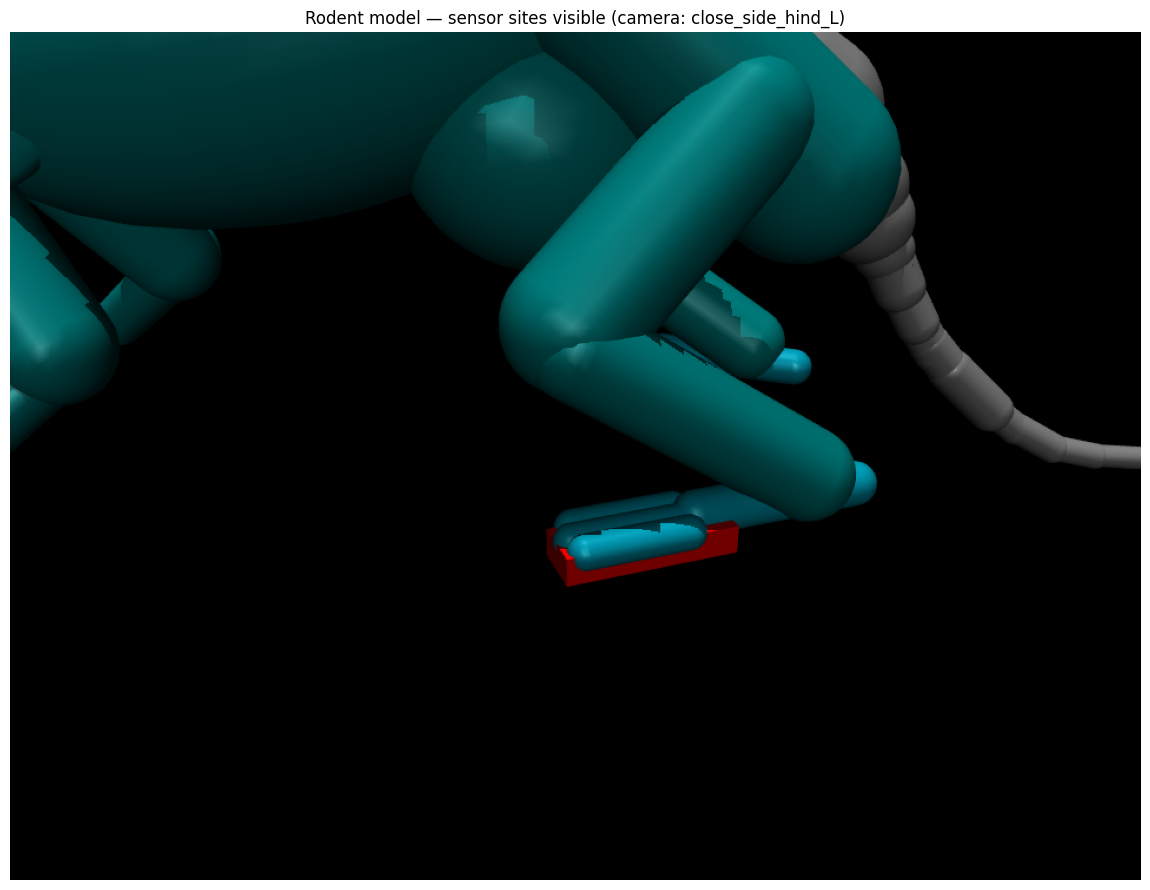


Site world positions (from mj_forward):
  sole_L: [-0.0278, 0.0343, 0.0048]
  sole_R: [-0.0278, -0.0343, 0.0048]
  palm_L: [0.0789, 0.0384, -0.0009]
  palm_R: [0.0799, -0.0384, -0.0009]
  head: [0.0972, 0.0000, 0.0725]


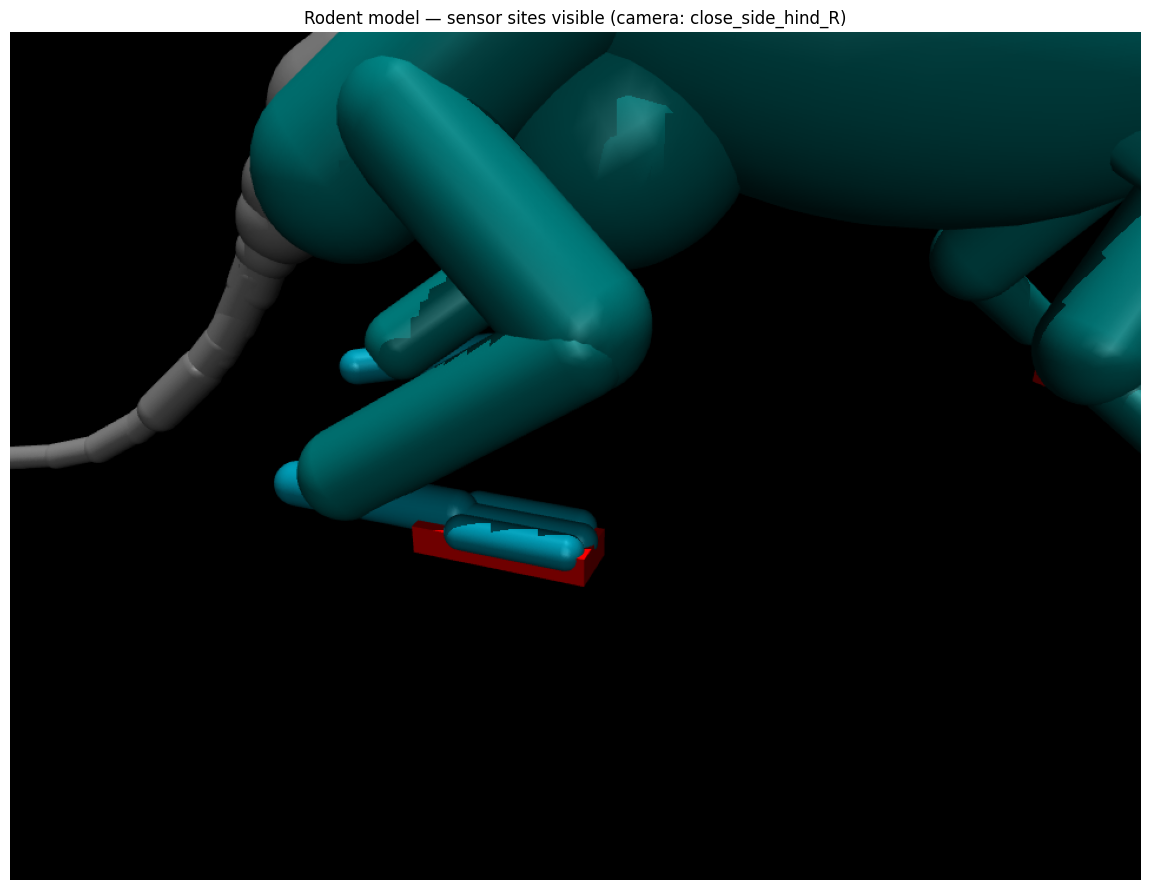


Site world positions (from mj_forward):
  sole_L: [-0.0278, 0.0343, 0.0048]
  sole_R: [-0.0278, -0.0343, 0.0048]
  palm_L: [0.0789, 0.0384, -0.0009]
  palm_R: [0.0799, -0.0384, -0.0009]
  head: [0.0972, 0.0000, 0.0725]


In [63]:
for cam in CAMERA_NAMES:
    # Render a single frame
    renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

    # Forward kinematics to compute positions
    mujoco.mj_forward(model, data)

    # Update scene with site visualization enabled
    renderer.update_scene(data, camera=cam, scene_option=scene_option)
    frame = renderer.render()

    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(frame)
    ax.set_title(f"Rodent model — sensor sites visible (camera: {cam})")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"\nSite world positions (from mj_forward):")
    for name in ["sole_L", "sole_R", "palm_L", "palm_R", "head"]:
        site_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, name)
        if site_id >= 0:
            pos = data.site_xpos[site_id]
            print(f"  {name}: [{pos[0]:.4f}, {pos[1]:.4f}, {pos[2]:.4f}]")

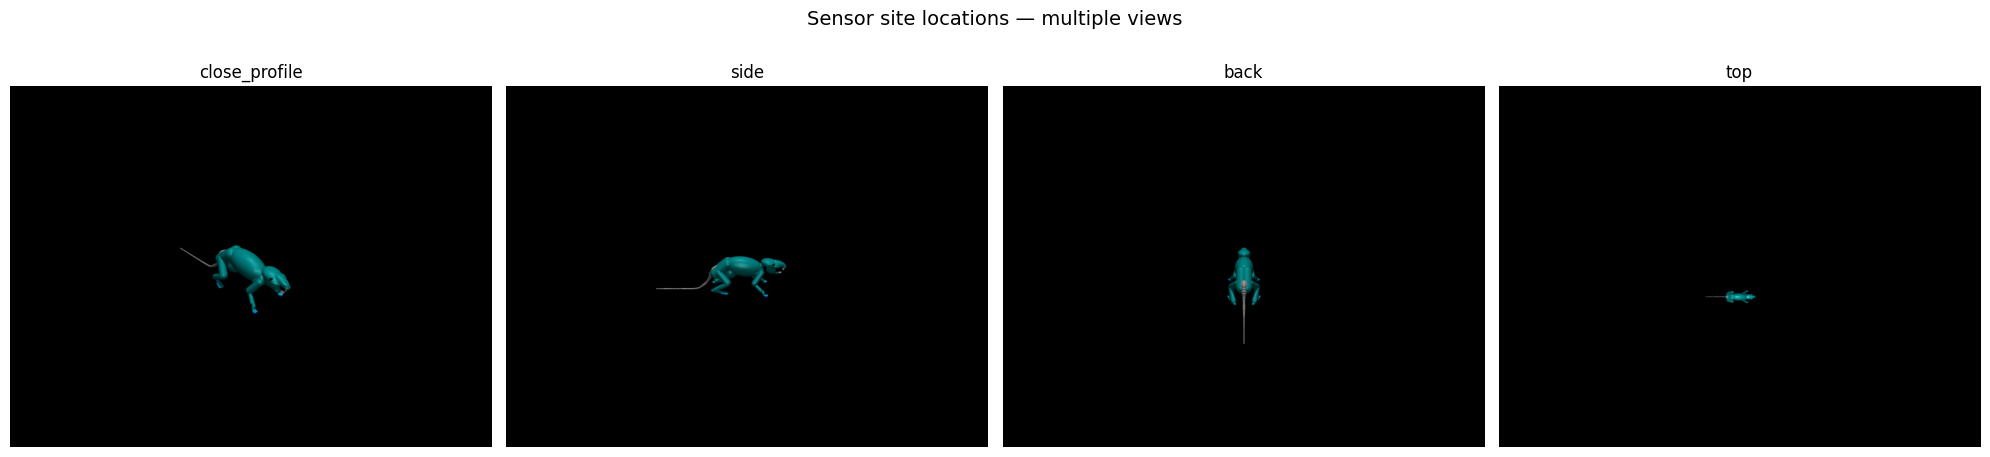

In [8]:
# Render multiple camera angles side by side
cameras = ["close_profile", "side", "back", "top"]

fig, axes = plt.subplots(1, len(cameras), figsize=(5 * len(cameras), 5))

for ax, cam_name in zip(axes, cameras):
    renderer.update_scene(data, camera=cam_name, scene_option=scene_option)
    frame = renderer.render()
    ax.imshow(frame)
    ax.set_title(cam_name)
    ax.axis("off")

plt.suptitle("Sensor site locations — multiple views", fontsize=14)
plt.tight_layout()
plt.show()

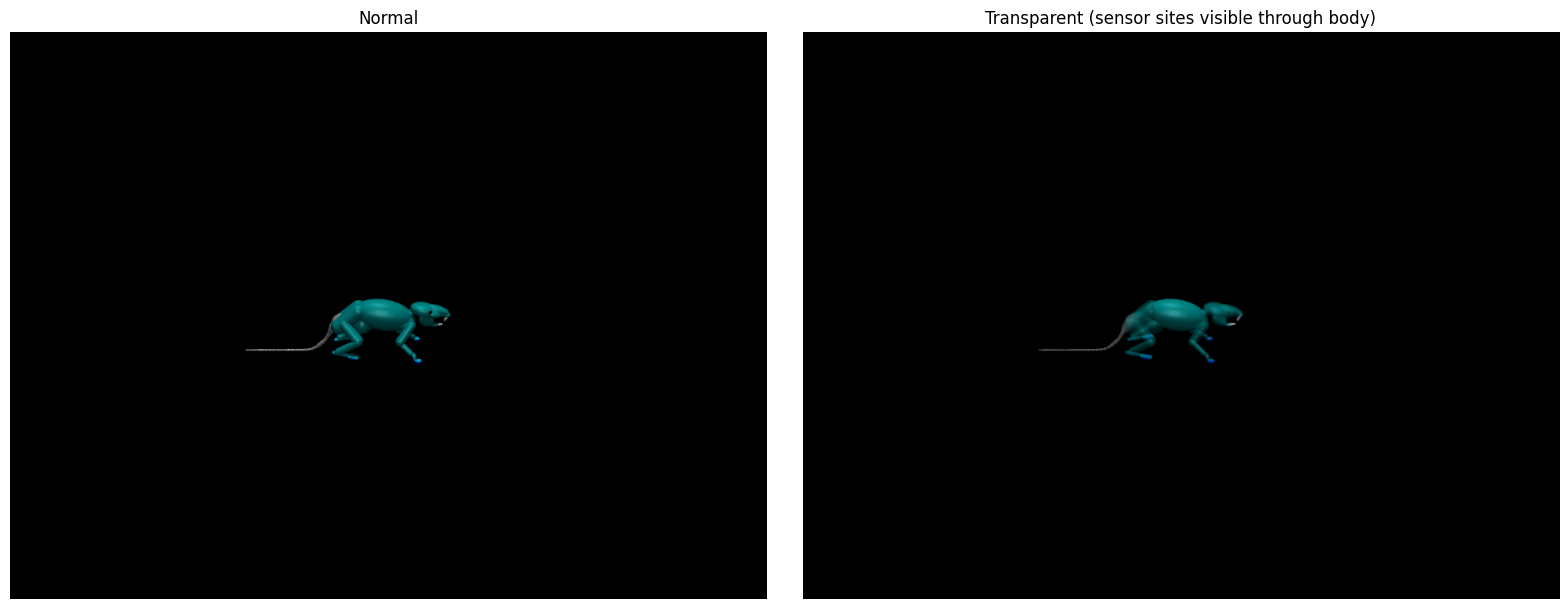

In [9]:
# Render with transparent bodies to see sensor sites inside/underneath
transparent_option = mujoco.MjvOption()
transparent_option.sitegroup[:] = [0, 0, 0, 0, 1, 0]
transparent_option.flags[mujoco.mjtVisFlag.mjVIS_TRANSPARENT] = True

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Normal
renderer.update_scene(data, camera=CAMERA_NAME, scene_option=scene_option)
frame_normal = renderer.render()
axes[0].imshow(frame_normal)
axes[0].set_title("Normal")
axes[0].axis("off")

# Transparent
renderer.update_scene(data, camera=CAMERA_NAME, scene_option=transparent_option)
frame_transparent = renderer.render()
axes[1].imshow(frame_transparent)
axes[1].set_title("Transparent (sensor sites visible through body)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Close-up of hind feet: position camera near foot_L
# Use a free camera aimed at the hind feet
foot_L_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "foot_L")
foot_R_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "foot_R")
foot_L_pos = data.xpos[foot_L_id]
foot_R_pos = data.xpos[foot_R_id]
foot_center = (foot_L_pos + foot_R_pos) / 2

cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_FREE
cam.lookat[:] = foot_center
cam.distance = 0.08  # Very close
cam.azimuth = 90  # Side view
cam.elevation = -20  # Slightly above

renderer.update_scene(data, camera=cam, scene_option=scene_option)
frame_feet = renderer.render()

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(frame_feet)
ax.set_title("Close-up: hind feet sensor sites (sole_L, sole_R)")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"foot_L body pos: {foot_L_pos}")
print(f"foot_R body pos: {foot_R_pos}")

sole_L_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, "sole_L")
sole_R_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, "sole_R")
print(f"sole_L site pos: {data.site_xpos[sole_L_id]}")
print(f"sole_R site pos: {data.site_xpos[sole_R_id]}")

In [ ]:
# Close-up of front paws
hand_L_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "finger_L")
hand_R_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "finger_R")
hand_L_pos = data.xpos[hand_L_id]
hand_R_pos = data.xpos[hand_R_id]
hand_center = (hand_L_pos + hand_R_pos) / 2

cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_FREE
cam.lookat[:] = hand_center
cam.distance = 0.08
cam.azimuth = 90
cam.elevation = -20

renderer.update_scene(data, camera=cam, scene_option=scene_option)
frame_hands = renderer.render()

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(frame_hands)
ax.set_title("Close-up: front paw sensor sites (palm_L, palm_R)")
ax.axis("off")
plt.tight_layout()
plt.show()

palm_L_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, "palm_L")
palm_R_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, "palm_R")
print(f"palm_L site pos: {data.site_xpos[palm_L_id]}")
print(f"palm_R site pos: {data.site_xpos[palm_R_id]}")

In [ ]:
renderer.close()